# Random Forest Regressor — Thermal Predictor

Modelo de regressão multi-output que prevê a temperatura de cada termopar
(`tc_name`) de uma `key_area` a partir das sete variáveis de configuração do ensaio.

**Entrada:** planilhas em formato wide geradas por `tratamento_final_dos_dados.ipynb`
(`data/<key_area>_data.csv`) — uma linha por run, uma coluna por termopar.

As sete planilhas têm o mesmo formato, mas diferem em número de linhas (55 a 73),
número de termopares (4 a 37) e, principalmente, em **quais sensores foram medidos
em quais runs**. Por isso o pipeline abaixo é escrito em funções que se adaptam ao
arquivo carregado, sem nenhum parâmetro fixo por área.

Rode as células em ordem. Para trocar de área, altere apenas `CAMINHO_PLANILHA`
na Célula 2 e execute o notebook novamente. A última célula roda as sete de uma vez.

## 1. Bibliotecas e configuração global

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
SEMENTE = 42

## 2. Parâmetros e leitura da planilha

Formato wide: cada termopar é uma coluna-alvo independente. Tudo que não está em
`VARIAVEIS_INDEPENDENTES` é candidato a alvo.

Duas checagens são feitas na leitura, porque nem toda coluna extra é um termopar
válido: colunas **sem nome** (`Unnamed: N`, geradas quando o `tc_name` original
estava em branco — é o caso de `ct_knobs_data.csv`) e colunas **inteiramente
vazias** são descartadas com aviso, em vez de entrarem como alvo do modelo.

In [ ]:
# ============================================================
# CÉLULA 2 — PARÂMETROS E LEITURA DA PLANILHA
# Formato wide: cada termopar é uma coluna-alvo independente
# ============================================================

# Troque aqui para rodar o modelo em outra key_area:
#   ../data/mainback_data.csv        ../data/ipc_comp_data.csv
#   ../data/coil_temps_data.csv      ../data/ipc_cooling_data.csv
#   ../data/main_vent_sys_data.csv   ../data/oven_hmi_data.csv
#   ../data/ct_knobs_data.csv
CAMINHO_PLANILHA = "../data/main_vent_sys_data.csv"

VARIAVEIS_INDEPENDENTES = [
    "blower_direction",
    "housing",
    "board_position",
    "run_case",
    "losses",
    "deflector_hole",
    "material_coil_support",
]

# Um termopar só entra como alvo se tiver leitura em pelo menos esta fração dos
# runs. Sensores abaixo disso são removidos como COLUNA — descartá-los custa um
# alvo, enquanto exigir que estejam presentes custaria quase todos os runs.
COBERTURA_MINIMA_ALVO = 0.50

# Número de folds do GridSearchCV. É reduzido automaticamente se o conjunto de
# treino for pequeno demais (ver Célula 5).
N_FOLDS_DESEJADO = 3


def identificar_alvos(df, independentes):
    """Separa as colunas-alvo válidas das colunas que não representam termopar."""
    alvos, descartadas = [], []
    for coluna in df.columns:
        if coluna in independentes:
            continue
        if str(coluna).startswith("Unnamed:") or not str(coluna).strip():
            descartadas.append((coluna, "coluna sem nome de termopar"))
        elif df[coluna].isna().all():
            descartadas.append((coluna, "coluna inteiramente vazia"))
        else:
            alvos.append(coluna)
    return alvos, descartadas


def resumir_alvos(df, alvos):
    """Tabela de cobertura e estatística descritiva de cada termopar."""
    return pd.DataFrame([
        {
            "termopar": alvo,
            "leituras": int(df[alvo].notna().sum()),
            "cobertura": df[alvo].notna().mean(),
            "min": df[alvo].min(),
            "max": df[alvo].max(),
            "média": df[alvo].mean(),
            "desvio": df[alvo].std(),
        }
        for alvo in alvos
    ]).sort_values("cobertura", ascending=False, ignore_index=True)


def listar_alvos_duplicados(df, alvos):
    """Pares de termopares com leitura idêntica (possível duplicação de sensor)."""
    return [
        (alvo_a, alvo_b)
        for i, alvo_a in enumerate(alvos)
        for alvo_b in alvos[i + 1:]
        if df[alvo_a].equals(df[alvo_b])
    ]


dados = pd.read_csv(CAMINHO_PLANILHA)
VARIAVEIS_ALVO, COLUNAS_DESCARTADAS = identificar_alvos(dados, VARIAVEIS_INDEPENDENTES)

print(f"Arquivo: {CAMINHO_PLANILHA}")
print(f"Linhas: {len(dados)} | Colunas: {dados.shape[1]}")

if COLUNAS_DESCARTADAS:
    print("\nColunas ignoradas (não são termopares válidos):")
    for coluna, motivo in COLUNAS_DESCARTADAS:
        print(f"   {coluna!r}: {motivo}")

print(f"\nTermopares candidatos ({len(VARIAVEIS_ALVO)}):")
print(resumir_alvos(dados, VARIAVEIS_ALVO).round(2).to_string(index=False))

print(f"\nValores nulos nos alvos: {int(dados[VARIAVEIS_ALVO].isna().sum().sum())}")

duplicadas = listar_alvos_duplicados(dados, VARIAVEIS_ALVO)
if duplicadas:
    print("\nATENÇÃO — colunas-alvo com valores idênticos:")
    for alvo_a, alvo_b in duplicadas:
        print(f"   {alvo_a}  ==  {alvo_b}")

dados.head()

Arquivo: ../data/main_vent_sys_data.csv
Linhas: 56 | Colunas: 14

Termopares candidatos (7):
                     termopar  leituras  cobertura   min    max  média  desvio
      AC Blower HES Connector        56       1.00 65.92 110.03  86.37    9.60
            AC Blower Housing        56       1.00 73.05 123.80  92.63   10.42
           AC Blower Windings        56       1.00 92.84 135.00 105.35    9.04
Turbo Duct / AC Blower Outlet        56       1.00 64.11  90.33  69.71    5.92
               Top Duct Inlet        56       1.00 41.56  62.28  47.69    4.68
          AC Blower Inlet Avg         4       0.07 64.28  83.13  75.92    8.35
          AC Blower Inlet Max         4       0.07 80.27 116.86  95.88   17.43

Valores nulos nos alvos: 104


,blower_direction,housing,board_position,run_case,losses,deflector_hole,material_coil_support,AC Blower HES Connector,AC Blower Housing,AC Blower Inlet Avg,AC Blower Inlet Max,AC Blower Windings,Top Duct Inlet,Turbo Duct / AC Blower Outlet
0,To back,Closed,Center,Broil C2,Simone Losses,Open,Aluminium,88.64,93.50,NaN,NaN,106.74,46.84,68.02
1,To back,Closed,Center,Broil C2,Simone Modified - Back Order,Closed,Aluminium,94.90,97.24,NaN,NaN,108.85,48.00,70.82
2,To back,Closed,Center,Broil Qualitative,Simone Losses,Open,Aluminium,88.72,93.96,NaN,NaN,106.96,46.30,68.14
3,To back,Open,Center,Broil C2,Simone Losses,Open,Aluminium,72.04,76.62,64.28,80.27,94.88,46.57,65.87
4,To back,Open,Center,Broil C2,Simone Losses,Open,Aluminium,72.10,76.67,NaN,NaN,96.59,46.18,66.02


## 3. Seleção de alvos, padronização das categorias e codificação

Esta é a célula que precisou mudar para o notebook funcionar nas sete áreas.

A versão anterior fazia `dropna(subset=VARIAVEIS_ALVO)` direto, ou seja, exigia que
**todos** os termopares tivessem leitura na mesma linha. Isso é *listwise deletion*:
basta um sensor pouco medido para eliminar quase todos os runs. Em
`main_vent_sys_data.csv`, dois sensores (`AC Blower Inlet Avg` e `Max`) só foram
medidos em 4 dos 56 runs, então a base caía de 56 para 4 linhas — 2 no treino, menos
que os 3 folds do `GridSearchCV`, o que produzia o `ValueError`.

A correção inverte a ordem: primeiro descarta o **sensor** com cobertura baixa,
depois descarta as **linhas** que ainda tenham buraco entre os alvos que sobraram.
No mesmo arquivo, a base passa de 4 para 56 linhas ao custo de 2 termopares.

In [ ]:
# ============================================================
# CÉLULA 3 — SELEÇÃO DE ALVOS, PADRONIZAÇÃO E CODIFICAÇÃO ORDINAL
# ============================================================
GRAFIAS_DIVERGENTES = {
    "blower_direction": {"To back": "To Back", "To front": "To Front"},
    "losses":           {"No losses": "No Losses"},
    "run_case":         {"Broil Case 2": "Broil C2", "Broil Qual": "Broil Qualitative", "Qualitative": "Broil Qualitative"},
    "housing":          {"Open - Updated": "Open"}
}


def filtrar_alvos_por_cobertura(df, alvos, cobertura_minima):
    """Mantém apenas os termopares medidos em uma fração mínima dos runs."""
    mantidos, removidos = [], []
    for alvo in alvos:
        cobertura = df[alvo].notna().mean()
        if cobertura >= cobertura_minima:
            mantidos.append(alvo)
        else:
            removidos.append((alvo, int(df[alvo].notna().sum()), cobertura))
    return mantidos, removidos


def padronizar_categorias(df, independentes, correcoes_por_variavel):
    """Unifica grafias divergentes e transforma nulos em categoria explícita."""
    df = df.copy()
    for variavel, correcoes in correcoes_por_variavel.items():
        if variavel in df.columns:
            df[variavel] = df[variavel].replace(correcoes)
    for variavel in independentes:
        df[variavel] = df[variavel].fillna("Nao Informado").astype(str)
    return df


def codificar_ordinal(df, independentes):
    """Codificação ordinal (0, 1, 2, ...) em ordem alfabética por variável."""
    X = df[independentes].copy()
    dicionario = {}
    for variavel in independentes:
        codigos = {categoria: i for i, categoria in enumerate(sorted(X[variavel].unique()))}
        dicionario[variavel] = codigos
        X[variavel] = X[variavel].map(codigos)
    return X, dicionario


# 1) Descarta o SENSOR pouco medido (coluna), não o run (linha).
VARIAVEIS_ALVO, alvos_removidos = filtrar_alvos_por_cobertura(
    dados, VARIAVEIS_ALVO, COBERTURA_MINIMA_ALVO
)

if alvos_removidos:
    print(f"Termopares removidos por cobertura < {COBERTURA_MINIMA_ALVO:.0%}:")
    for alvo, leituras, cobertura in alvos_removidos:
        print(f"   {alvo:40s} {leituras:3d}/{len(dados)} runs ({cobertura:.1%})")
    print()

if not VARIAVEIS_ALVO:
    raise ValueError(
        f"Nenhum termopar atingiu a cobertura mínima de {COBERTURA_MINIMA_ALVO:.0%}. "
        f"Reduza COBERTURA_MINIMA_ALVO na Célula 2 para modelar este arquivo."
    )

# 2) Só agora descarta as LINHAS com buraco entre os alvos que sobraram.
dados_tratados = dados.dropna(subset=VARIAVEIS_ALVO).copy()

linhas_removidas = len(dados) - len(dados_tratados)
if linhas_removidas:
    print(f"Linhas removidas por alvo ausente: {linhas_removidas}\n")

dados_tratados = padronizar_categorias(
    dados_tratados, VARIAVEIS_INDEPENDENTES, GRAFIAS_DIVERGENTES
)
X, dicionario_codificacao = codificar_ordinal(dados_tratados, VARIAVEIS_INDEPENDENTES)
Y = dados_tratados[VARIAVEIS_ALVO]

print("Dicionário de codificação:\n")
for variavel, codigos in dicionario_codificacao.items():
    print(f"{variavel} ({len(codigos)} categorias)")
    for categoria, codigo in codigos.items():
        print(f"   {codigo:>2d} = {categoria}")
    print()

print(f"Matriz de features: {X.shape}")
print(f"Colunas-alvo: {len(VARIAVEIS_ALVO)}")
print(f"Linhas úteis: {len(dados_tratados)} de {len(dados)}")
print(f"Combinações distintas de configuração: {X.drop_duplicates().shape[0]}")

Termopares removidos por cobertura < 50%:
   AC Blower Inlet Avg                        4/56 runs (7.1%)
   AC Blower Inlet Max                        4/56 runs (7.1%)



Dicionário de codificação:

blower_direction (2 categorias)
    0 = To Back
    1 = To Front

housing (2 categorias)
    0 = Closed
    1 = Open

board_position (2 categorias)
    0 = Center
    1 = Right

run_case (4 categorias)
    0 = Broil C1
    1 = Broil C2
    2 = Broil Qualitative
    3 = Pyro

losses (14 categorias)
    0 = Broil C2 Simone - 240/145/180/180
    1 = Broil C2 Simone - Front Order
    2 = Broil Miro - Front Order
    3 = C1 Simone - 240/145/180/180
    4 = Miro
    5 = Miro - Front Order
    6 = Miro Qualitative  - Back Order
    7 = Miro Qualitative  - Front Order
    8 = No Losses
    9 = Não informado
   10 = Qual Simone - Front Order
   11 = Simone
   12 = Simone Losses
   13 = Simone Modified - Back Order

deflector_hole (2 categorias)
    0 = Closed
    1 = Open

material_coil_support (3 categorias)
    0 = Aluminium 
    1 = Aluminium Plate
    2 = Plastic 

Matriz de features: (56, 7)
Colunas-alvo: 5
Linhas úteis: 56 de 56
Combinações distintas de configu

## 4. Separação treino (70%) / teste (20%) / verificação (10%)

`Y` é matricial: uma coluna por termopar, lida de `dados_tratados` para permanecer
alinhada com as linhas de `X`.

A célula checa antes da divisão se sobraram linhas suficientes para formar os três
conjuntos e ainda alimentar a validação cruzada, e falha com uma mensagem que diz o
que ajustar — em vez do `ValueError` genérico do `GridSearchCV` duas células adiante.

In [ ]:
# ============================================================
# CÉLULA 4 — SEPARAÇÃO TREINO (70%) / TESTE (20%) / VERIFICAÇÃO (10%)
# Y é matricial (uma coluna por termopar)
# ============================================================
PROPORCAO_TREINO = 0.70
PROPORCAO_TESTE = 0.20
PROPORCAO_VERIFICACAO = 0.10

MINIMO_DE_LINHAS = 10
if len(X) < MINIMO_DE_LINHAS:
    raise ValueError(
        f"Apenas {len(X)} linhas úteis após o tratamento — insuficiente para dividir em "
        f"treino/teste/verificação e rodar validação cruzada. Verifique a Célula 3: "
        f"provavelmente há termopares esparsos derrubando linhas. Considere reduzir "
        f"COBERTURA_MINIMA_ALVO (hoje {COBERTURA_MINIMA_ALVO:.0%}) na Célula 2."
    )

X_treino, X_restante, Y_treino, Y_restante = train_test_split(
    X, Y,
    train_size=PROPORCAO_TREINO,
    random_state=SEMENTE,
)

proporcao_verificacao_no_restante = (
    PROPORCAO_VERIFICACAO / (PROPORCAO_TESTE + PROPORCAO_VERIFICACAO)
)

X_teste, X_verificacao, Y_teste, Y_verificacao = train_test_split(
    X_restante, Y_restante,
    test_size=proporcao_verificacao_no_restante,
    random_state=SEMENTE,
)

print(f"Treino:       {len(X_treino):3d} linhas ({len(X_treino)/len(X):.1%})")
print(f"Teste:        {len(X_teste):3d} linhas ({len(X_teste)/len(X):.1%})")
print(f"Verificação:  {len(X_verificacao):3d} linhas ({len(X_verificacao)/len(X):.1%})")
print(f"\nFormato de X: {X_treino.shape}  |  Formato de Y: {Y_treino.shape}")

Treino:        39 linhas (69.6%)
Teste:         11 linhas (19.6%)
Verificação:    6 linhas (10.7%)

Formato de X: (39, 7)  |  Formato de Y: (39, 5)


## 5. Treinamento do modelo (Random Forest multi-output)

`RandomForestRegressor` suporta múltiplas saídas nativamente: cada folha armazena
um vetor de médias, uma por termopar.

O número de folds é `min(N_FOLDS_DESEJADO, linhas de treino)`, com mínimo de 2 —
antes era fixo em 3, o que quebrava quando o conjunto de treino ficava menor que
isso. Com o filtro de cobertura da Célula 3 esse caso deixa de ocorrer nas sete
áreas atuais, mas o limite protege contra planilhas menores no futuro.

Melhores hiperparâmetros:
   max_depth: 3
   max_features: sqrt
   min_samples_leaf: 1
   n_estimators: 100

Saídas do modelo: 5 termopares

Importância das variáveis:
run_case                 0.2910
losses                   0.2437
blower_direction         0.1947
deflector_hole           0.1435
housing                  0.1019
board_position           0.0182
material_coil_support    0.0070


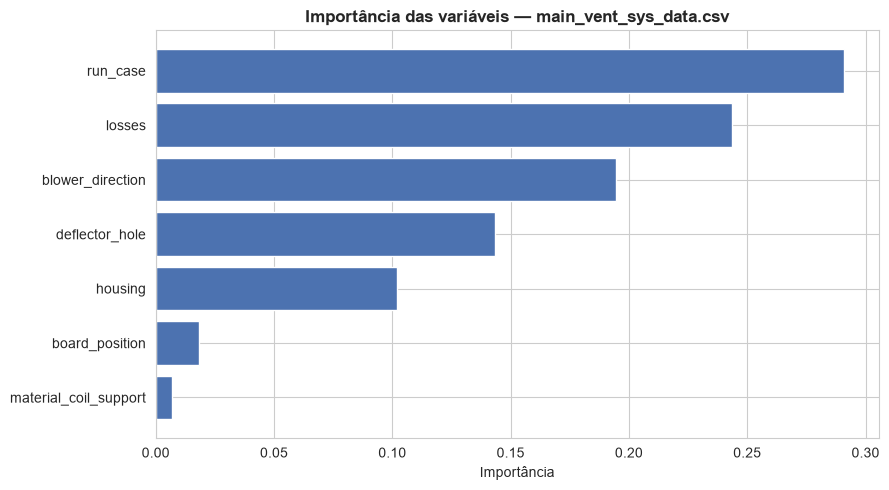

In [ ]:
# ============================================================
# CÉLULA 5 — TREINAMENTO DO MODELO (RANDOM FOREST MULTI-OUTPUT)
# RandomForestRegressor suporta múltiplas saídas nativamente:
# cada folha armazena um vetor de médias, uma por termopar.
# ============================================================
GRADE_HIPERPARAMETROS = {
    "n_estimators":     [100, 300],
    "max_depth":        [3, 5, None],
    "min_samples_leaf": [1, 2],
    "max_features":     ["sqrt", None],
}

# Nunca pedir mais folds do que há linhas de treino.
n_folds = max(2, min(N_FOLDS_DESEJADO, len(X_treino)))
if n_folds < N_FOLDS_DESEJADO:
    print(f"Aviso: {len(X_treino)} linhas de treino — usando {n_folds} folds "
          f"em vez de {N_FOLDS_DESEJADO}.\n")

busca = GridSearchCV(
    estimator=RandomForestRegressor(random_state=SEMENTE, n_jobs=-1),
    param_grid=GRADE_HIPERPARAMETROS,
    cv=n_folds,                 # poucas linhas: 3 folds em vez de 5
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)
busca.fit(X_treino, Y_treino)

modelo = busca.best_estimator_

print("Melhores hiperparâmetros:")
for parametro, valor in busca.best_params_.items():
    print(f"   {parametro}: {valor}")

print(f"\nSaídas do modelo: {modelo.n_outputs_} termopares")

# A importância é única para o modelo — reflete todos os alvos em conjunto
importancia = (
    pd.Series(modelo.feature_importances_, index=VARIAVEIS_INDEPENDENTES)
      .sort_values(ascending=False)
)
print(f"\nImportância das variáveis:\n{importancia.round(4).to_string()}")

plt.figure(figsize=(9, 5))
plt.barh(importancia.index[::-1], importancia.values[::-1], color="#4C72B0")
plt.xlabel("Importância")
plt.title(f"Importância das variáveis — {CAMINHO_PLANILHA.split('/')[-1]}",
          fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Avaliação estatística por termopar

MAE, MSE, RMSE, R² e MAPE calculados coluna a coluna nos três conjuntos, seguidos
da média entre termopares e da fração de previsões dentro da margem de 10%
acordada com o parceiro.

In [ ]:
# ============================================================
# CÉLULA 6 — AVALIAÇÃO ESTATÍSTICA POR TERMOPAR
# ============================================================
def avaliar_multioutput(Y_real, Y_previsto, nome_conjunto, alvos):
    """Calcula métricas para cada coluna-alvo separadamente."""
    linhas = []
    for indice, termopar in enumerate(alvos):
        real = Y_real.iloc[:, indice].values
        previsto = Y_previsto[:, indice]
        mse = mean_squared_error(real, previsto)
        linhas.append({
            "conjunto": nome_conjunto,
            "termopar": termopar,
            "MAE":      mean_absolute_error(real, previsto),
            "MSE":      mse,
            "RMSE":     np.sqrt(mse),
            "R2":       r2_score(real, previsto),
            "MAPE_%":   np.mean(np.abs((real - previsto) / real)) * 100,
        })
    return linhas


previsoes_treino      = modelo.predict(X_treino)
previsoes_teste       = modelo.predict(X_teste)
previsoes_verificacao = modelo.predict(X_verificacao)

avaliacao = pd.DataFrame(
    avaliar_multioutput(Y_treino,      previsoes_treino,      "Treino",      VARIAVEIS_ALVO)
  + avaliar_multioutput(Y_teste,       previsoes_teste,       "Teste",       VARIAVEIS_ALVO)
  + avaliar_multioutput(Y_verificacao, previsoes_verificacao, "Verificação", VARIAVEIS_ALVO)
)

print("=" * 100)
print(f"DESEMPENHO POR TERMOPAR — {CAMINHO_PLANILHA}")
print("=" * 100)
print(avaliacao.round(4).to_string(index=False))

print("\n" + "=" * 100)
print("MÉDIA ENTRE OS TERMOPARES")
print("=" * 100)
print(
    avaliacao.groupby("conjunto", sort=False)[["MAE", "MSE", "RMSE", "R2", "MAPE_%"]]
             .mean().round(4).to_string()
)

erro_percentual_teste = np.abs((Y_teste.values - previsoes_teste) / Y_teste.values)
print(f"\nPrevisões dentro da margem de 10% (teste, todos os termopares): "
      f"{(erro_percentual_teste <= 0.10).mean():.1%}")

DESEMPENHO POR TERMOPAR — ../data/main_vent_sys_data.csv
   conjunto                      termopar    MAE     MSE   RMSE      R2  MAPE_%
     Treino       AC Blower HES Connector 4.3033 54.5846 7.3881  0.4185  5.0404
     Treino             AC Blower Housing 4.5453 48.8375 6.9884  0.4847  4.8211
     Treino            AC Blower Windings 3.6717 45.8063 6.7680  0.4265  3.3693
     Treino                Top Duct Inlet 1.7523 11.2171 3.3492  0.4549  3.5012
     Treino Turbo Duct / AC Blower Outlet 2.0943 12.9040 3.5922  0.5501  2.8914
      Teste       AC Blower HES Connector 3.0039 16.4652 4.0577  0.7319  3.5486
      Teste             AC Blower Housing 4.6707 45.0802 6.7142  0.6440  4.8990
      Teste            AC Blower Windings 3.2959 31.6766 5.6282  0.6583  2.8776
      Teste                Top Duct Inlet 2.3264 15.4647 3.9325  0.5419  4.3864
      Teste Turbo Duct / AC Blower Outlet 3.8874 37.8045 6.1485  0.3748  4.8854
Verificação       AC Blower HES Connector 5.0295 36.8971 6.0743

## 7. Execução em lote — as sete áreas

Encadeia as funções das células anteriores em um único pipeline e roda as sete
planilhas em sequência, para conferir de uma vez que nenhuma delas quebra e
comparar o desempenho entre áreas. É opcional: as células 2 a 6 continuam sendo o
caminho para analisar uma área em detalhe.

In [ ]:
# ============================================================
# CÉLULA 7 — EXECUÇÃO EM LOTE NAS SETE PLANILHAS
# ============================================================
PLANILHAS = [
    "../data/mainback_data.csv",
    "../data/coil_temps_data.csv",
    "../data/main_vent_sys_data.csv",
    "../data/ct_knobs_data.csv",
    "../data/ipc_comp_data.csv",
    "../data/ipc_cooling_data.csv",
    "../data/oven_hmi_data.csv",
]


def treinar_area(caminho, cobertura_minima=COBERTURA_MINIMA_ALVO, n_folds_desejado=N_FOLDS_DESEJADO):
    """Pipeline completo de uma planilha: leitura, tratamento, treino e avaliação."""
    df = pd.read_csv(caminho)
    alvos, _ = identificar_alvos(df, VARIAVEIS_INDEPENDENTES)
    alvos, removidos = filtrar_alvos_por_cobertura(df, alvos, cobertura_minima)
    if not alvos:
        raise ValueError(f"{caminho}: nenhum termopar com cobertura >= {cobertura_minima:.0%}")

    tratado = df.dropna(subset=alvos)
    tratado = padronizar_categorias(tratado, VARIAVEIS_INDEPENDENTES, GRAFIAS_DIVERGENTES)
    X_area, _ = codificar_ordinal(tratado, VARIAVEIS_INDEPENDENTES)
    Y_area = tratado[alvos]

    X_tr, X_resto, Y_tr, Y_resto = train_test_split(
        X_area, Y_area, train_size=PROPORCAO_TREINO, random_state=SEMENTE)
    X_te, X_ve, Y_te, Y_ve = train_test_split(
        X_resto, Y_resto,
        test_size=PROPORCAO_VERIFICACAO / (PROPORCAO_TESTE + PROPORCAO_VERIFICACAO),
        random_state=SEMENTE)

    busca_area = GridSearchCV(
        estimator=RandomForestRegressor(random_state=SEMENTE, n_jobs=-1),
        param_grid=GRADE_HIPERPARAMETROS,
        cv=max(2, min(n_folds_desejado, len(X_tr))),
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    ).fit(X_tr, Y_tr)

    modelo_area = busca_area.best_estimator_
    metricas_teste = pd.DataFrame(
        avaliar_multioutput(Y_te, modelo_area.predict(X_te), "Teste", alvos))
    erro_pct = np.abs((Y_te.values - modelo_area.predict(X_te)) / Y_te.values)

    return {
        "planilha": caminho.split("/")[-1],
        "linhas": len(tratado),
        "alvos": len(alvos),
        "alvos_removidos": len(removidos),
        "MAE_teste": metricas_teste["MAE"].mean(),
        "RMSE_teste": metricas_teste["RMSE"].mean(),
        "R2_teste": metricas_teste["R2"].mean(),
        "MAPE_teste_%": metricas_teste["MAPE_%"].mean(),
        "dentro_de_10%": (erro_pct <= 0.10).mean(),
    }


resultados = []
for caminho in PLANILHAS:
    try:
        resultados.append(treinar_area(caminho))
        print(f"OK   {caminho}")
    except Exception as erro:
        print(f"FALHA {caminho}: {type(erro).__name__}: {erro}")

comparativo = pd.DataFrame(resultados)
print("\n" + "=" * 110)
print("COMPARATIVO ENTRE ÁREAS — métricas médias no conjunto de teste")
print("=" * 110)
print(comparativo.round(4).to_string(index=False))

OK   ../data/mainback_data.csv


OK   ../data/coil_temps_data.csv


OK   ../data/main_vent_sys_data.csv


OK   ../data/ct_knobs_data.csv


OK   ../data/ipc_comp_data.csv


OK   ../data/ipc_cooling_data.csv


OK   ../data/oven_hmi_data.csv

COMPARATIVO ENTRE ÁREAS — métricas médias no conjunto de teste
              planilha  linhas  alvos  alvos_removidos  MAE_teste  RMSE_teste  R2_teste  MAPE_teste_%  dentro_de_10%
     mainback_data.csv      54     10                0     4.8575      7.6796    0.1905        8.0575         0.7091
   coil_temps_data.csv      49      8                0    10.4689     15.3964    0.8463        9.3973         0.6750
main_vent_sys_data.csv      56      5                2     3.4369      5.2962    0.5902        4.1194         0.8545
     ct_knobs_data.csv      55      6                0     2.2319      3.0248    0.4200        4.7612         0.8636
     ipc_comp_data.csv      24     37                0     6.9593      8.3161   -0.6802       10.4481         0.6108
  ipc_cooling_data.csv      53      4                0     4.3939      8.3062    0.2135        5.8409         0.8750
     oven_hmi_data.csv      55      4                0     1.8242      2.2625    0.397